# PLN — Features de texto dos chamados

A etapa de **PLN** lê o `title` e a `description` de cada chamado e gera **cinco colunas numéricas** para o classificador multimodal.

- **Parte 1:** o que é cada coluna e como interpretá-la.
- **Parte 2:** como as colunas foram geradas.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yaml

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 80)

# Execução mais recente do pipeline com o PLN semântico
EXECUCAO = sorted(p.parent.name for p in (RAIZ / "reports" / "runs").glob("*/enriched.parquet")
                  if "text_failure_similarity" in pd.read_parquet(p).columns)[-1]
DIR = RAIZ / "reports" / "runs" / EXECUCAO

df = pd.read_parquet(DIR / "enriched.parquet")
cfg_pln = yaml.safe_load((DIR / "models.yaml").read_text(encoding="utf-8"))["modelos"]["pln"]
COLUNAS = [o["name"] for o in cfg_pln["outputs"]]
print("Execução:", EXECUCAO, "| chamados:", len(df))

Execução: 20261031T011846_46cef21f | chamados: 5000


---
## Parte 1 — O que é cada coluna

| Coluna | O que mede | Intervalo | Como ler |
| --- | --- | --- | --- |
| `sentiment_score` | Tom do relato | −1 a 1 | Negativo = insatisfação; perto de 0 = neutro; positivo = satisfação |
| `text_failure_similarity` | Parecença com um relato de **falha** ("não funciona", "parou") | −1 a 1 | Quanto maior, mais o texto soa como algo quebrado |
| `text_access_request_similarity` | Parecença com um **pedido de acesso** (conta, senha, permissão) | −1 a 1 | Quanto maior, mais o texto soa como pedido de liberação |
| `text_guidance_similarity` | Parecença com uma **dúvida** ou pedido de orientação | −1 a 1 | Quanto maior, mais o texto soa como pergunta |
| `text_performance_similarity` | Parecença com um relato de **lentidão** ou travamento | −1 a 1 | Quanto maior, mais o texto soa como problema de desempenho |

Pontos importantes:

- `sentiment_score` **substitui** a coluna original do dataset; as outras quatro são **novas**.
- As quatro similaridades **não são probabilidades**: não somam 1 e podem ser altas ao mesmo tempo (um chamado pode ser falha *e* lentidão). O que importa é o valor ser mais alto ou mais baixo que o comum.

Exemplos reais:

In [2]:
df.drop_duplicates("title").sample(5, random_state=7)[["title"] + COLUNAS + ["target_category"]].round(3)

,title,sentiment_score,text_failure_similarity,text_access_request_similarity,text_guidance_similarity,text_performance_similarity,target_category
1081,Erro de permissão no Sistema de Notas Fiscais durante a impr...,-0.018,0.474,0.492,0.288,0.155,Software
2387,Falha no SAP: superaquece ao tentar importar dados.,-0.041,0.228,0.204,0.311,0.359,Software
3106,O usuário não consegue exportar dados devido a apresenta err...,-0.025,0.481,0.280,0.129,0.143,Acesso
1113,Erro de runtime no SAP durante a abrir documento.,0.055,0.373,0.289,0.270,0.399,Software
1729,O usuário relata tela preta ao tentar acessar sistema de fol...,0.023,0.311,0.502,0.352,0.498,Acesso


In [3]:
df[COLUNAS].describe().T[["mean", "std", "min", "max"]].round(3)

,mean,std,min,max
sentiment_score,-0.022,0.044,-0.219,0.124
text_failure_similarity,0.387,0.111,0.078,0.728
text_access_request_similarity,0.259,0.117,-0.056,0.680
text_guidance_similarity,0.263,0.082,0.040,0.625
text_performance_similarity,0.340,0.110,0.054,0.751


Na prática, as similaridades ficam quase todas entre 0 e 0,75, e o sentimento fica **muito perto de zero**: os chamados são frases curtas e descritivas, sem emoção explícita.

### Essas colunas têm relação com a categoria?

O PLN não usa a categoria para gerar as colunas, mas dá para conferir depois se elas variam por categoria. A comparação usa **só o treino**, para não orientar decisões pelo teste:

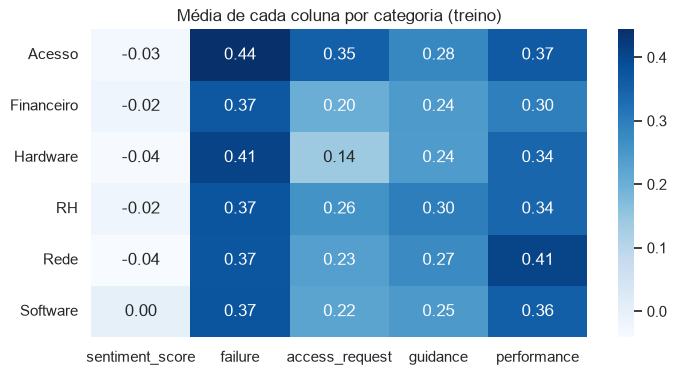

In [4]:
treino = df[df["split"] == "train"]
medias = treino.groupby("target_category")[COLUNAS].mean()
medias.columns = [c.replace("text_", "").replace("_similarity", "") for c in COLUNAS]

plt.figure(figsize=(8, 4))
sns.heatmap(medias, annot=True, fmt=".2f", cmap="Blues")
plt.title("Média de cada coluna por categoria (treino)")
plt.ylabel("")
plt.show()

- **access_request** é a coluna mais útil: bem mais alta em **Acesso**.
- **performance** é mais alta em **Rede**.
- **failure** e **guidance** variam pouco entre as categorias.
- **sentiment** é praticamente igual em todas, então ajuda pouco.

Nenhuma coluna separa as categorias sozinha; o classificador final combina essas colunas com o texto, a imagem e os dados tabulares.

---
## Parte 2 — Como as colunas foram geradas

```text
title + description
        │
        ├──► Modelo NLI ─────────► compara com 3 frases de "tom" ──────► sentiment_score
        │
        └──► Encoder de frases ──► compara com 12 frases-exemplo ──────► 4 similaridades
```

Regras gerais da etapa:

- **Nenhum modelo é treinado.** As duas redes são pré-treinadas (Hugging Face) e usadas só para inferência.
- **A categoria (`target_category`) nunca é usada.** O PLN gera sinais, não tenta adivinhar a categoria.
- **Tudo é configurado no YAML** (`src/config/models.yaml`, bloco `modelos.pln`) e implementado em `src/models/language.py` e `src/models/semantic_text.py`.
- **Textos repetidos são processados uma única vez** e o resultado é reaproveitado.

### Sentimento: NLI *zero-shot*

O modelo `MoritzLaurer/multilingual-MiniLMv2-L6-mnli-xnli` faz **inferência textual (NLI)**: recebe o texto do chamado e uma frase-hipótese e diz o quanto o texto **confirma** a hipótese. O projeto usa três hipóteses, cada uma com um valor:

In [5]:
pd.DataFrame(cfg_pln["sentiment"]["candidates"])[["value", "hypothesis"]]

,value,hypothesis
0,-1.0,"O solicitante expressa insatisfação, frustração ou uma experiência negativa."
1,0.0,O solicitante apresenta uma informação ou pedido de forma neutra.
2,1.0,"O solicitante expressa satisfação, agradecimento ou uma experiência positiva."


1. O modelo pontua o quanto o chamado confirma cada hipótese.
2. As três pontuações viram probabilidades que somam 1 (*softmax*).
3. `sentiment_score = p(negativo)·(−1) + p(neutro)·0 + p(positivo)·(+1)`.

Como a hipótese neutra sempre fica com boa parte da probabilidade, os valores ficam comprimidos perto de zero.

### Similaridades: *embeddings* e frases-exemplo

O modelo `sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2` transforma uma frase em um **vetor de 384 números** que representa seu significado. Frases com sentido parecido ficam com vetores próximos, mesmo com palavras diferentes.

No YAML há **3 frases-exemplo para cada grupo**:

In [6]:
pd.DataFrame([(grupo, frase) for grupo, frases in cfg_pln["semantic"]["prototypes"].items() for frase in frases],
             columns=["coluna", "frase-exemplo"])

,coluna,frase-exemplo
0,text_failure_similarity,O sistema apresenta um erro e não funciona.
1,text_failure_similarity,O equipamento parou de funcionar e preciso de reparo.
2,text_failure_similarity,Não consigo realizar minha atividade porque o serviço está indisponível.
3,text_access_request_similarity,Solicito criação de uma conta e liberação de acesso.
4,text_access_request_similarity,Preciso de permissão para utilizar o sistema.
5,text_access_request_similarity,Quero redefinir minha senha para acessar minha conta.
6,text_guidance_similarity,Tenho uma dúvida e preciso de orientação para usar o sistema.
7,text_guidance_similarity,Gostaria de saber como realizar esta operação.
8,text_guidance_similarity,Solicito informações e instruções sobre o serviço.
9,text_performance_similarity,O sistema está lento e demora muito para responder.


1. O título e a descrição viram vetores (separadamente) e são somados com peso igual.
2. As 12 frases-exemplo também viram vetores.
3. Calcula-se a **similaridade de cosseno** entre o chamado e cada frase-exemplo (1 = mesmo sentido, 0 = sem relação).
4. Cada coluna recebe o **maior cosseno** entre o chamado e as 3 frases do seu grupo.

### Onde isso está no código

O comando `python -m src.data.pipeline --features` (ou `--train-multimodal`) chega ao PLN por este caminho:

| Passo | Arquivo → função | O que faz |
| --- | --- | --- |
| 1 | `src/models/features_pipeline.py` → `run_features` | Percorre as etapas do YAML; o campo `adapter: semantic_nlp` escolhe a classe `SemanticNLP` (dicionário `ADAPTERS`) |
| 2 | `src/models/language.py` → `SemanticNLP.fit` | **Não treina nada:** baixa/carrega as duas redes congeladas e transforma as 12 frases-exemplo em vetores |
| 3 | `src/models/language.py` → `SemanticNLP.transform` | Gera as 5 colunas para cada partição (treino, validação e teste) |
| 3a | `language.py` → `ContextualNLP.probabilities` + `weighted_score` | Sentimento: pontuação NLI das 3 hipóteses → softmax → média ponderada |
| 3b | `src/models/semantic_text.py` → `SemanticTextEncoder.encode_frame` / `encode` | Similaridades: texto → vetor (média dos tokens, normalizado) e soma título + descrição (`combine_fields`) |
| 3c | `semantic_text.py` → `intent_similarities` | Cosseno com as frases-exemplo e o **maior valor por grupo** |
| 4 | `features_pipeline.py` → `merge_outputs` | Junta as colunas ao dataset: `sentiment_score` **substitui** a original, as outras são **adicionadas** |
| 5 | `language.py` → `SemanticNLP.save` | Salva as redes e as frases-exemplo codificadas em `models/runs/<execução>/pln/` |

A célula abaixo mostra o código **atual** das funções que calculam as colunas, lido direto dos arquivos do projeto:

In [7]:
import inspect, sys
sys.path.insert(0, str(RAIZ))

from src.models.language import SemanticNLP, weighted_score
from src.models.semantic_text import combine_fields, intent_similarities

print("Classe usada pelo YAML desta execução:", cfg_pln["adapter"], "→", SemanticNLP.__name__)
for funcao in (SemanticNLP.transform, weighted_score, combine_fields, intent_similarities):
    print(f"\n{'=' * 20} {funcao.__qualname__}  ({Path(inspect.getsourcefile(funcao)).relative_to(RAIZ).as_posix()}) {'=' * 20}")
    print(inspect.getsource(funcao))

Classe usada pelo YAML desta execução: semantic_nlp → SemanticNLP

==================== SemanticNLP.transform  (src/models/language.py) ====================
    def transform(self, data: pd.DataFrame) -> pd.DataFrame:
        """Substitui sentimento e gera apenas as similaridades declaradas no YAML.

        Preserva o cálculo anterior do sentimento. O encoder semântico normaliza
        espaços, deduplica textos e combina título/descrição com pesos iguais.
        """
        from src.data.processor import require_columns
        from src.models.semantic_text import intent_similarities

        require_columns(data, self.config["features"], "PLN semântico")
        if data.empty:
            raise ValueError("Nenhum chamado para enriquecer")
        texts = data[self.config["features"]].astype("string").fillna("").agg("\n".join, axis=1)
        if texts.str.strip().eq("").any():
            raise ValueError("Título e descrição não podem estar ambos vazios")
        unique = texts.drop

Lendo o código acima:

- **`SemanticNLP.transform`** junta título e descrição, remove textos repetidos, calcula o sentimento (`probabilities` + `weighted_score`), gera os vetores (`encode_frame`) e chama `intent_similarities`. No fim, devolve as colunas na ordem declarada em `outputs` no YAML.
- **`weighted_score`** é a média ponderada `probabilidades @ valores` (−1, 0, 1).
- **`combine_fields`** normaliza os vetores de título e descrição, soma os dois e normaliza de novo.
- **`intent_similarities`** faz `vetores @ exemplos.T` (o cosseno, porque os vetores têm norma 1) e pega o `.max()` de cada grupo.

### Limitações

- As colunas dependem das **frases escolhidas no YAML**: trocar os exemplos muda os valores.
- As similaridades medem **palavras e estrutura da frase**, não o assunto. Por exemplo, frases com "Erro de permissão" ficam com alta similaridade de acesso, mesmo rotuladas como Software.
- O dataset é **sintético**: frases curtas, montadas por modelos de texto e muito repetidas. Em chamados reais o comportamento pode ser diferente.
- O ganho real dessas colunas no classificador final só pode ser confirmado treinando o multimodal **com e sem elas** na mesma divisão (ablação).